In [2]:
from matplotlib import pyplot as plt
import pandas as pds
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.cluster import KMeans


from sklearn.manifold import MDS

%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [3]:
# Data preprocessing
df = pds.read_csv("../data/Life_Expectancy_Data.csv") # gonna use this dataset for both task 1 and task 2 ig
df = df.dropna(subset=["Life expectancy ", " BMI ",
                            "infant deaths",
                            "Alcohol",
                            " thinness  1-19 years"])
df_chosen_variables = df[["Country", "Life expectancy ", " BMI ","infant deaths",
                               "Alcohol", " thinness  1-19 years"]]

countries = ['Afghanistan', 'Albania', 'New Zealand', 'Norway','Singapore'] 
df_chosen_countries = df_chosen_variables[df_chosen_variables['Country'].isin(countries)]

df_chosen_countries['Country'].unique()

array(['Afghanistan', 'Albania', 'New Zealand', 'Norway', 'Singapore'],
      dtype=object)

In [9]:
df_chosen_countries = df_chosen_countries.reset_index(drop=True)

# Standardize the features
# Create an object of StandardScaler which is present in sklearn.preprocessing
scalar = StandardScaler() 
scaled = pds.DataFrame(scalar.fit_transform(df_chosen_countries.select_dtypes(include='number')))


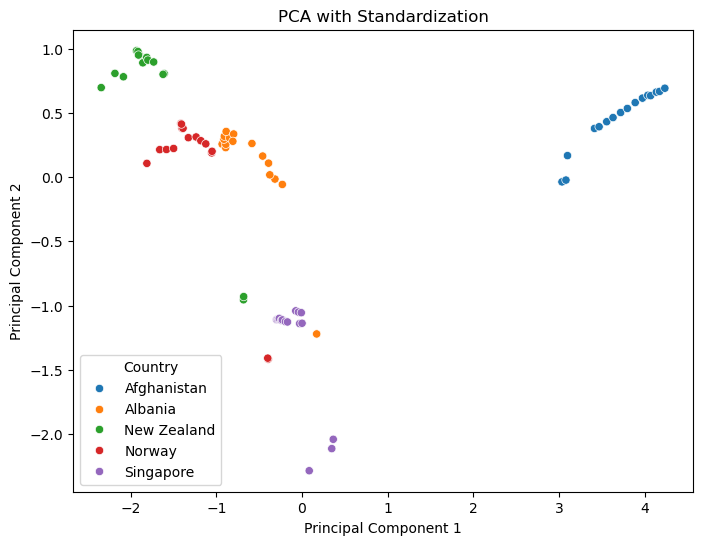

In [13]:
#Applying PCA with standardized data
#Taking no. of Principal Components as 2
pca = PCA(n_components = 2)
pca.fit(scaled)
data_pca = pca.transform(scaled)
data_pca = pds.DataFrame(data_pca,columns=['PC1','PC2'])
data_pca['Country'] = df_chosen_countries['Country']

plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', hue='Country', data=data_pca)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA with Standardization')
plt.show()

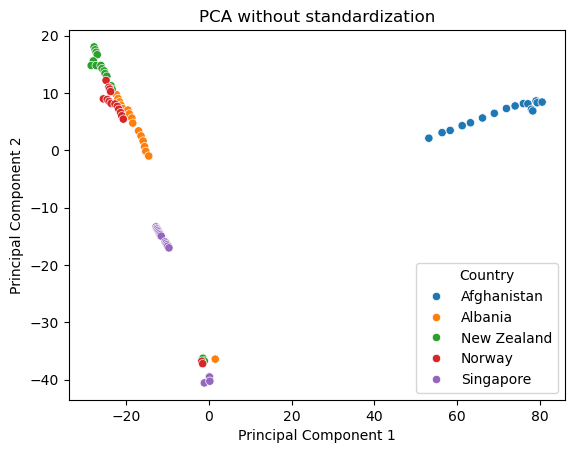

In [14]:
#Applying PCA with normal data
#Taking no. of Principal Components as 2
pca = PCA(n_components = 2)
pca.fit(df_chosen_countries.select_dtypes(include='number'))
data_pca = pca.transform(df_chosen_countries.select_dtypes(include='number'))
data_pca = pds.DataFrame(data_pca,columns=['PC1','PC2'])
data_pca['Country'] = df_chosen_countries['Country']
sns.scatterplot(x='PC1', y='PC2', hue='Country', data=data_pca)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA without standardization')
plt.show()

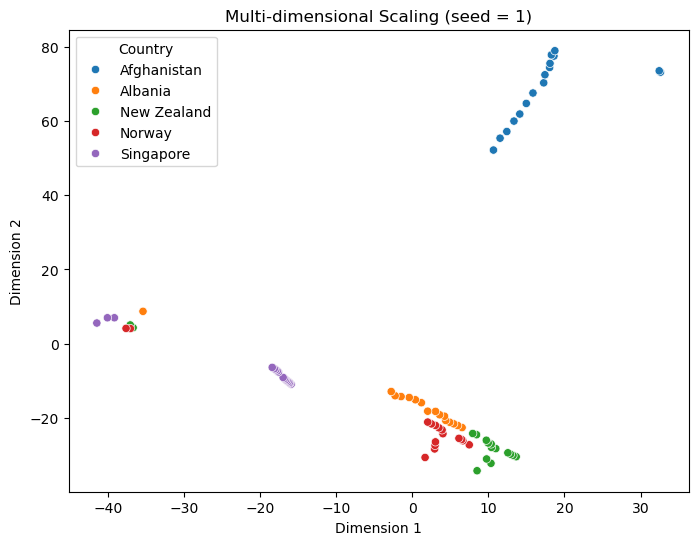

In [15]:
# MDS

# Country code for coloring
country_codes = pds.factorize(df_chosen_countries['Country'])[0]
# Create an MDS model with the desired number of dimensions
# Number of dimensions for visualization  
mds = MDS(n_components = 2,n_init = 4, random_state = 1)

# Fit the MDS model to your data
data_reduced = mds.fit_transform(df_chosen_countries.select_dtypes(include='number'))

# Visualize the reduced data
df_plot = pds.DataFrame({
    'Dim1': data_reduced[:,0],
    'Dim2': data_reduced[:,1],
    'Country': df_chosen_countries['Country']
})

plt.figure(figsize=(8,6))
sns.scatterplot(x='Dim1', y='Dim2', hue='Country', data=df_plot)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.title('Multi-dimensional Scaling (seed = 1)')
plt.show()


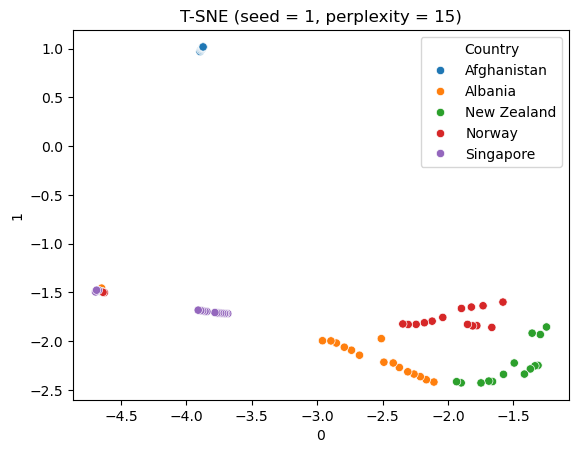

In [38]:
# t-SNE
from sklearn.manifold import TSNE

tsne = TSNE(n_components = 2, perplexity = 50, random_state = 0)
tsne.fit(df_chosen_countries.select_dtypes(include='number'))
data_tsne = tsne.fit_transform(df_chosen_countries.select_dtypes(include='number'))
data_tsne = pds.DataFrame(data_tsne,columns=['0','1'])
data_tsne['Country'] = df_chosen_countries['Country']
sns.scatterplot(x='0', y='1', hue='Country', data=data_tsne)
plt.xlabel('0')
plt.ylabel('1')
plt.title('T-SNE (seed = 1, perplexity = 15)')
plt.show()
